# NB 00 · Reconnaissance du data lake

**Rôle joué :** analyste d'une cellule de veille OSINT. Avant d'exploiter une source, un analyste du renseignement **évalue sa fiabilité**. Un modèle d'IA entraîné sur une source pourrie produit du renseignement pourri, même avec 99 % de précision.

**Mission de ce notebook :**
1. Faire l'inventaire physique du data lake (quoi, combien, quel poids).
2. Profiler chaque source (colonnes, trous, doublons).
3. Zoomer sur les 3 sources stratégiques : presse Golfe 2026, Telegram Ukraine 2022-23, vérité terrain Ormuz.
4. Faire du **contre-espionnage de données** : détecter les jeux truqués et les fuites qui font tricher un modèle.
5. Rendre un verdict par source avec une note inspirée du **code de l'Amirauté (OTAN)**.

> **Le code de l'Amirauté** note chaque source de **A** (complètement fiable) à **F** (impossible à juger). Les services de renseignement l'utilisent encore aujourd'hui pour coter leurs informations. On l'applique ici à nos jeux de données.

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import ast

import matplotlib.pyplot as plt
import pandas as pd

from spirit_digger.config import CAMPS_TELEGRAM, OUTPUTS, SOURCES
from spirit_digger.loaders import charger
from spirit_digger.style import ACCENT, ALERTE, OK, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 100)
bandeau("NB 00 · Reconnaissance du data lake", "Avant de creuser, on évalue la fiabilité de chaque source.")

## 1. Inventaire physique

Première question d'un analyste : **qu'est-ce que j'ai sous la main ?**

In [2]:
inventaire = pd.DataFrame([
    {"source": nom, "dossier": chemin.parent.name, "fichier": chemin.name,
     "taille_Mo": round(chemin.stat().st_size / 1e6, 1)}
    for nom, chemin in SOURCES.items()
]).sort_values("taille_Mo", ascending=False, ignore_index=True)

print(f"{len(inventaire)} sources · {inventaire.taille_Mo.sum():.0f} Mo au total")
inventaire

12 sources · 790 Mo au total


,source,dossier,fichier,taille_Mo
0,telegram_ru_ua,news_but_in_russian_lg,news.csv,280.1
1,welfake,WELFake_Dataset,WELFake_Dataset.csv,245.1
2,misinfo_fake,MisInfo_propagande,DataSet_Misinfo_FAKE.csv,116.7
3,misinfo_true,MisInfo_propagande,DataSet_Misinfo_TRUE.csv,114.4
4,cyber_synth,cybersecurity synthesized data,cybersecurity synthesized data.csv,14.7
5,rumeurs,rumor_dataset,rumor_dataset.csv,7.8
6,iran_us_news,iran_us_news_dataset,iran_us_news_dataset.csv,7.5
7,propagande_ru,MisInfo_propagande,EXTRA_RussianPropagandaSubset.csv,2.0
8,trending,global_trending_topics,global_trending_topics.csv,1.7
9,cyber_threats,Cybersecurity_Dataset,Cybersecurity_Dataset.csv,0.2


## 2. Profil de chaque source

On charge tout en mémoire (environ 15 secondes) et on mesure pour chaque source : nombre de lignes, cellules vides et doublons exacts.

In [3]:
bruts = {nom: charger(nom) for nom in SOURCES}

profil = pd.DataFrame([{
    "source": nom,
    "lignes": len(df),
    "colonnes": df.shape[1],
    "cellules_vides_%": round(100 * df.isna().mean().mean(), 1),
    "doublons_%": round(100 * df.duplicated().mean(), 1),
    "colonnes_principales": ", ".join(map(str, df.columns[:5])),
} for nom, df in bruts.items()]).sort_values("lignes", ascending=False, ignore_index=True)
profil

,source,lignes,colonnes,cellules_vides_%,doublons_%,colonnes_principales
0,telegram_ru_ua,386889,5,0.0,0.0,"id, group_id, group_name, text, date"
1,cyber_synth,100000,15,0.0,0.0,"attack_type, target_system, outcome, timestamp, attacker_ip"
2,welfake,72134,3,0.3,11.7,"title, text, label"
3,rumeurs,62445,4,5.1,1.3,"text, is_rumor, user.handle, topic"
4,misinfo_fake,43642,1,0.0,21.9,text
5,misinfo_true,34975,1,0.1,1.3,text
6,propagande_ru,7369,1,0.0,18.0,text
7,trending,6960,18,2.6,0.0,"date, year, month, week, day_of_week"
8,iran_us_news,2286,6,11.2,0.0,"link, title, content, date, _source"
9,cyber_threats,1100,15,0.0,0.0,"Threat Category, IOCs (Indicators of Compromise), Threat Actor, Attack Vector, Geographical Loca..."


> **Cas d'école : un fichier corrompu.** Le fichier `posts_information/posts.csv` (Reddit r/geopolitics) a des retours à la ligne non protégés **et** contient un morceau d'un autre fichier collé dedans. On utilise donc `top_by_score.csv` à la place. Vérification :

In [4]:
corrompu = pd.read_csv(SOURCES["reddit_geopol"].parent / "posts.csv", skiprows=1,
                       on_bad_lines="skip", engine="python")
print(f"posts.csv : 100 posts annoncés, {corrompu['title'].notna().sum()} titres lisibles")
print("Colonne « subreddit » (on ne devrait y voir que « geopolitics ») :")
corrompu["subreddit"].astype(str).str[:70].value_counts().head(4)

posts.csv : 100 posts annoncés, 26 titres lisibles
Colonne « subreddit » (on ne devrait y voir que « geopolitics ») :


subreddit
0              4
1              3
geopolitics    2
DDoS           2
Name: count, dtype: int64

## 3. Zoom sur les sources stratégiques

### 3.1 Théâtre GOLFE : presse Iran / États-Unis 2025-2026

2286 articles · 67% SANS DATE


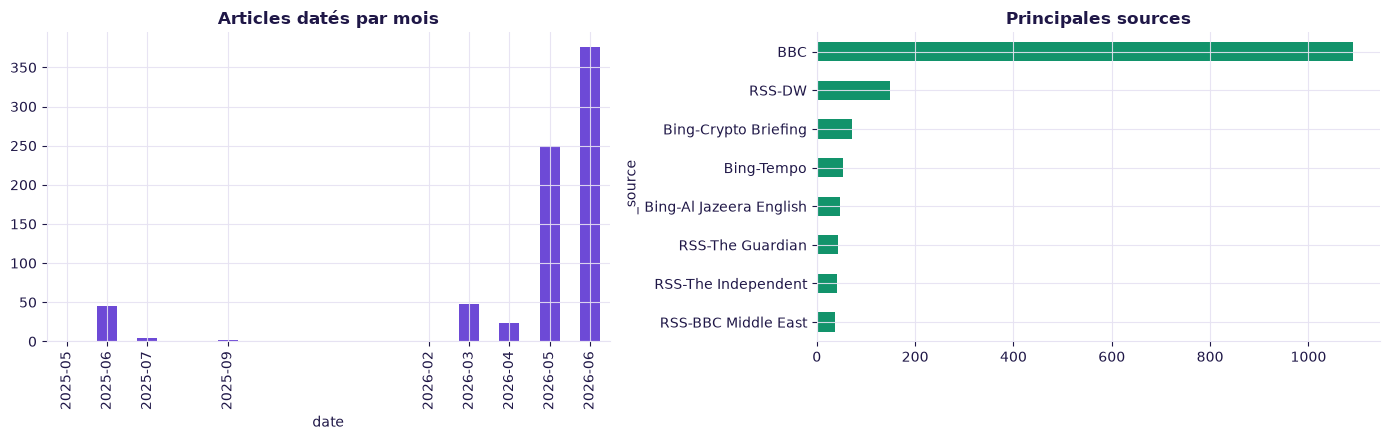

_keyword
rss                        350
Iran US conflict 2026      184
Iran ceasefire 2026        176
Strait of Hormuz crisis    175
Ali Khamenei death         136
US Iran sanctions 2026     134
Iran US war 2025           133
Iran supreme leader        132
Iran oil blockade          128
Iran Trump 2026            125
Name: count, dtype: int64

In [5]:
iran = bruts["iran_us_news"].copy()
iran["date"] = pd.to_datetime(iran["date"], errors="coerce")
print(f"{len(iran)} articles · {iran['date'].isna().mean():.0%} SANS DATE")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
iran["date"].dt.to_period("M").value_counts().sort_index().plot.bar(ax=axes[0], color=ACCENT)
axes[0].set_title("Articles datés par mois")
iran["_source"].value_counts().head(8).sort_values().plot.barh(ax=axes[1], color=OK)
axes[1].set_title("Principales sources")
plt.tight_layout()
plt.show()

iran["_keyword"].value_counts().head(10)

**Lecture analyste :** deux articles sur trois n'ont pas de date, et le corpus ne démarre vraiment qu'en mai 2026, après la fermeture d'Ormuz (28/02/2026). On **ne peut donc pas** l'utiliser pour de l'alerte précoce. En revanche, il est très riche pour **l'inventaire des acteurs (NER)** et **le graphe de relations**.

### 3.2 Théâtre UKRAINE : 387 000 messages Telegram (février 2022 à juillet 2023)

Douze chaînes, cinq « camps » : médias d'État russes, presse ukrainienne, médias russes en exil, médias internationaux. C'est la source idéale pour le **recoupement** : une information confirmée par des camps qui se détestent est très solide.

386,889 messages du 24/02/2022 au 03/07/2023


,messages,chaînes
camp,,
Ukraine,151785,"Shocked Ukraine, Ukraine Now, Ukraine24, УНИАН"
Russie - État,138755,"RIA News, TASS"
Russe indépendant (exil),36163,"Meduza, Novaya Gazeta"
Russie - presse sous contrainte,31995,RBK
International,28191,"BBC Russia, The New York Times, Washington Post"


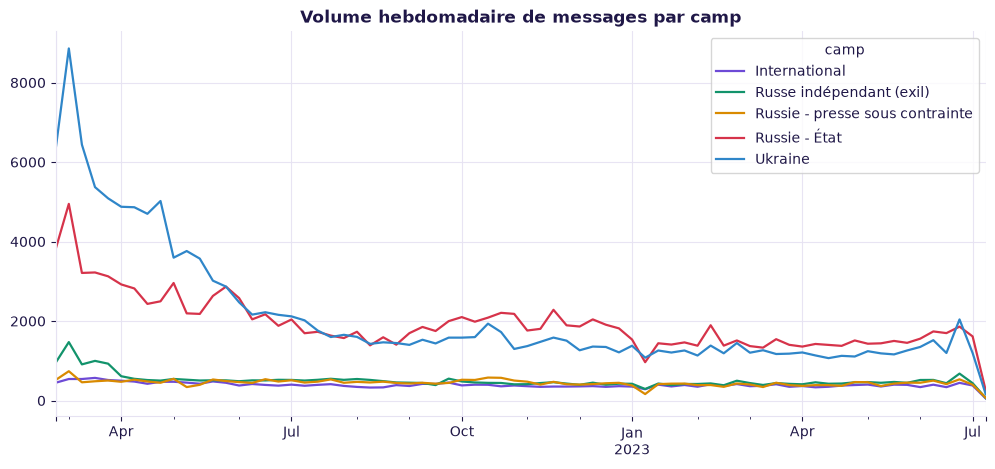

In [6]:
tg = bruts["telegram_ru_ua"].copy()
tg["date"] = pd.to_datetime(tg["date"], errors="coerce")
tg["camp"] = tg["group_name"].map(CAMPS_TELEGRAM)

print(f"{len(tg):,} messages du {tg.date.min():%d/%m/%Y} au {tg.date.max():%d/%m/%Y}")
display(tg.groupby("camp")["group_name"].agg(["size", lambda s: ", ".join(sorted(s.unique()))])
          .set_axis(["messages", "chaînes"], axis=1).sort_values("messages", ascending=False))

hebdo = tg.groupby([pd.Grouper(key="date", freq="W"), "camp"]).size().unstack(fill_value=0)
hebdo.plot(title="Volume hebdomadaire de messages par camp", lw=1.6)
plt.xlabel("")
plt.show()

#### Avant-goût du NB 03 : un signal faible

On cherche simplement le nom **Пригожин** (Prigojine, chef du groupe Wagner) dans les messages de mai-juin 2023, et on compte **combien de sources différentes** en parlent chaque jour.

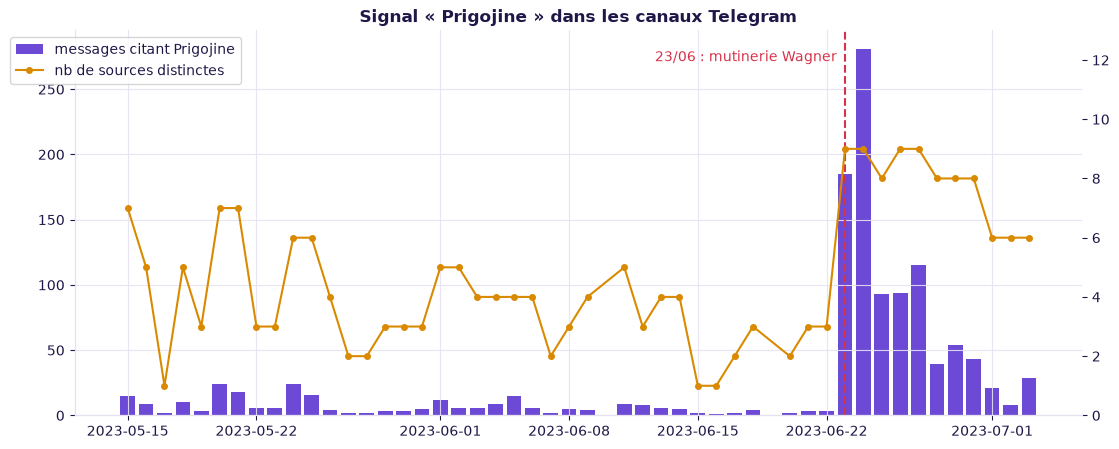

In [7]:
mentions = tg[(tg.date >= "2023-05-15") & tg["text"].str.lower().str.contains("пригожин", na=False)]
signal = mentions.groupby("date").agg(messages=("id", "size"), sources=("group_name", "nunique"))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(signal.index, signal.messages, color=ACCENT, label="messages citant Prigojine")
ax2 = ax.twinx()
ax2.plot(signal.index, signal.sources, color=VEILLE, marker="o", ms=4, label="nb de sources distinctes")
ax2.set_ylim(0, 13)
ax2.grid(False)
ax.axvline(pd.Timestamp("2023-06-23"), color=ALERTE, ls="--")
ax.text(pd.Timestamp("2023-06-23"), ax.get_ylim()[1] * 0.92, "23/06 : mutinerie Wagner  ", color=ALERTE, ha="right")
ax.set_title("Signal « Prigojine » dans les canaux Telegram")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
plt.show()

**Lecture analyste :** on passe de 3 messages par jour à 185 le 23 juin, et de 3 à 9 sources, **tous camps confondus**. Au NB 03, Spirit Digger détectera ce genre de rupture **automatiquement**, sans connaître le mot à l'avance.

### 3.3 Vérité terrain : trafic maritime dans le détroit d'Ormuz (2026)

Ce n'est pas du texte. Ce sont des **mesures physiques** (navires par jour, attaques, prix du pétrole) avec un journal d'événements. Elles serviront à **valider** ce que l'IA lit dans la presse.

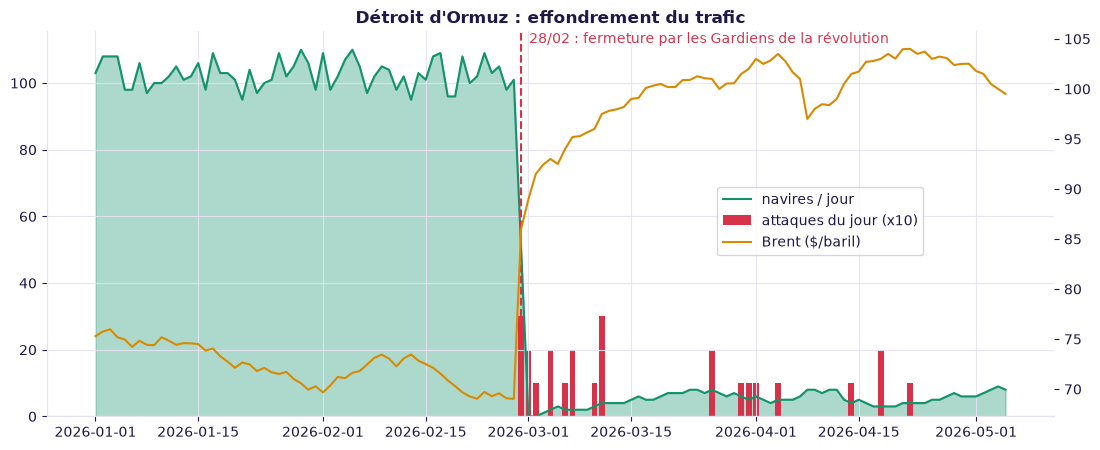

,date,daily_ship_transits,new_attacks_today,key_event
45,2026-02-15,101,0,Insurance premiums rising; Iran pre-positioning signals (SeaVantage)
58,2026-02-28,50,3,US-Israel strikes Iran; Khamenei assassinated; IRGC closes Hormuz; 3 tankers struck near Oman
59,2026-03-01,0,2,No tankers broadcast AIS signals in strait; Maersk/CMA CGM/Hapag suspend transits
60,2026-03-02,0,1,IRGC officially closes strait to 'unfriendly nations'; Ebrahim Jabari warns ships will be set ab...
62,2026-03-04,2,2,IRGC claims 'complete control' of strait; Chinese bulk carrier Iron Maiden transits signalling C...
63,2026-03-05,3,0,LPG tanker Bogazici transits broadcasting Muslim/Turkish ownership; war risk P&I insurance withd...
64,2026-03-06,2,1,"Tugboat assisting Safeen Prestige struck by 2 missiles, sinks; 3 crew missing"
65,2026-03-07,2,2,IRGC hits oil tanker Prima and US tanker Louis P with drones in Persian Gulf/strait
68,2026-03-10,3,1,US intelligence: Iran begins planting naval mines; Trump demands removal; US destroys 16 Iranian...
69,2026-03-11,4,3,"Large wave of attacks: Thai bulk carrier Mayuree Naree struck, smoke visible; 3 vessels damaged"


In [8]:
hz = bruts["hormuz"].copy()
hz["date"] = pd.to_datetime(hz["date"])
ROUTINE = {"Normal operations", "Strait remains largely closed; carriers maintain Cape reroute"}

fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(hz.date, hz.daily_ship_transits, color=OK, alpha=0.35)
ax.plot(hz.date, hz.daily_ship_transits, color=OK, label="navires / jour")
ax2 = ax.twinx()
ax2.plot(hz.date, hz.brent_crude_usd_bbl, color=VEILLE, label="Brent ($/baril)")
ax2.grid(False)
ax.bar(hz.date, hz.new_attacks_today * 10, color=ALERTE, width=0.8, label="attaques du jour (x10)")
ax.axvline(pd.Timestamp("2026-02-28"), color=ALERTE, ls="--")
ax.text(pd.Timestamp("2026-02-28"), 112, "  28/02 : fermeture par les Gardiens de la révolution", color=ALERTE)
ax.set_title("Détroit d'Ormuz : effondrement du trafic")
fig.legend(loc="center", bbox_to_anchor=(0.72, 0.5))
plt.show()

hz.loc[~hz.key_event.isin(ROUTINE), ["date", "daily_ship_transits", "new_attacks_today", "key_event"]] \
  .drop_duplicates("key_event").head(12)

**Lecture analyste :** le journal signale dès le **15/02** des « primes d'assurance en hausse » et des « signaux de pré-positionnement iranien », **13 jours avant la fermeture**. Le trafic, lui, reste parfaitement normal jusqu'au 27/02. C'est la définition même d'un **signal faible** : il est dans le texte bien avant d'être dans les chiffres.

## 4. Contre-espionnage des données

Un bon analyste se méfie. Deux pièges classiques :
- **Les données synthétiques déguisées :** elles ont l'air réelles, mais elles ont été générées au hasard.
- **Les fuites (data leakage) :** un détail sans rapport avec le fond (crédit photo, nom d'agence) trahit la réponse, et le modèle « triche ».

### 4.1 Le jeu « Cybersecurity_Dataset » est-il crédible ?

In [9]:
cy = bruts["cyber_threats"]

accord = (cy["Threat Category"] == cy["Predicted Threat Category"]).mean()
hasard = 1 / cy["Threat Category"].nunique()
print(f"Accord catégorie réelle / « prédite » : {accord:.1%}  (pur hasard = {hasard:.0%})")

iocs = cy["IOCs (Indicators of Compromise)"].dropna().map(ast.literal_eval).explode()
print(f"Indicateurs de compromission : {len(iocs)} au total, {iocs.nunique()} valeurs distinctes")
print("Exemple d'IP « 123.456.78.9 » : un octet vaut au maximum 255, cette adresse ne peut pas exister.")
print(f"Descriptions distinctes : {cy['Cleaned Threat Description'].nunique()} pour {len(cy)} menaces\n")

pd.crosstab(cy["Threat Category"], cy["Topic Modeling Labels"])

Accord catégorie réelle / « prédite » : 24.7%  (pur hasard = 25%)
Indicateurs de compromission : 1976 au total, 9 valeurs distinctes
Exemple d'IP « 123.456.78.9 » : un octet vaut au maximum 255, cette adresse ne peut pas exister.
Descriptions distinctes : 5 pour 1100 menaces



Topic Modeling Labels,DDoS,Malware,Phishing,Ransomware
Threat Category,,,,
DDoS,51,48,103,52
Malware,51,65,117,61
Phishing,53,71,107,65
Ransomware,55,47,99,55


**Verdict :** la « prédiction » ne fait pas mieux que le hasard. Il n'y a que 9 indicateurs, dont une IP impossible, et 5 phrases recyclées. Les catégories et les sujets sont répartis uniformément : **c'est un jeu généré aléatoirement**. Même constat pour `cybersecurity synthesized data` : ses variables numériques ont une corrélation nulle entre elles.

In [10]:
bruts["cyber_synth"].select_dtypes("number").corr().round(2)

,data_compromised_GB,attack_duration_min,attack_severity,response_time_min
data_compromised_GB,1.0,-0.0,-0.0,-0.0
attack_duration_min,-0.0,1.0,-0.0,-0.0
attack_severity,-0.0,-0.0,1.0,-0.0
response_time_min,-0.0,-0.0,-0.0,1.0


### 4.2 Fuites dans le jeu « vrai / faux » (MisInfo, issu du jeu ISOT)

On compte la part d'articles contenant certains marqueurs **qui n'ont rien à voir avec la véracité**.

In [11]:
vrai = bruts["misinfo_true"]["text"].fillna("")
faux = bruts["misinfo_fake"]["text"].fillna("")
propa = bruts["propagande_ru"]["text"].fillna("")

MARQUEURS = {
    "crédit « Getty Images »": r"Getty Images",
    "« Featured image »": r"[Ff]eatured [Ii]mage",
    "lien pic.twitter": r"pic\.twitter",
    "URL http": r"https?://",
    "style agence « said on <jour> »": r"said on (?:Monday|Tuesday|Wednesday|Thursday|Friday)",
}
fuites = pd.DataFrame({
    "% articles VRAIS": [100 * vrai.str.contains(m).mean() for m in MARQUEURS.values()],
    "% articles FAUX": [100 * faux.str.contains(m).mean() for m in MARQUEURS.values()],
}, index=list(MARQUEURS)).round(1)
display(fuites)

print("Longueur médiane (caractères) :",
      f"vrai={vrai.str.len().median():.0f} · faux={faux.str.len().median():.0f} · propagande={propa.str.len().median():.0f}")

,% articles VRAIS,% articles FAUX
crédit « Getty Images »,0.0,9.3
« Featured image »,0.0,19.2
lien pic.twitter,0.0,9.2
URL http,0.0,10.4
style agence « said on <jour> »,20.9,0.5


Longueur médiane (caractères) : vrai=2394 · faux=1949 · propagande=195


**Lecture analyste :** un modèle naïf apprendra que « Getty Images » ou un lien Twitter signifie « faux ». Il obtiendra 99 % de précision en test et s'effondrera sur le terrain. On nettoiera ces signatures au NB 01. On note aussi que les textes de propagande sont **10 fois plus courts** : la longueur seule trahirait la classe, il faudra tronquer.

### 4.3 WELFake : un jeu de test vraiment indépendant ?

In [12]:
from spirit_digger.cleaning import empreinte

emp_isot = set(pd.concat([vrai, faux]).map(empreinte))
emp_wel = set(bruts["welfake"]["text"].fillna("").map(empreinte))
commun = len(emp_wel & emp_isot)
print(f"{commun:,} des {len(emp_wel):,} textes uniques de WELFake ({commun / len(emp_wel):.0%}) sont DÉJÀ dans ISOT.")

41,214 des 62,207 textes uniques de WELFake (66%) sont DÉJÀ dans ISOT.


**Verdict :** WELFake contient en grande partie les mêmes articles. Si on s'en sert pour tester un modèle entraîné sur ISOT, il faudra **retirer les doublons**, sinon le score sera gonflé.

## 5. Verdict : registre des sources

La fiabilité suit l'échelle de l'Amirauté : A complètement fiable · B habituellement fiable · C assez fiable · D peu fiable · E non fiable · F impossible à juger.

In [13]:
registre = pd.DataFrame([
    ("telegram_ru_ua", "B", "RETENU", "Théâtre UKRAINE : alerte précoce, recoupement multi-camps, guerre de l'information",
     "12 chaînes identifiées, datées, camps opposés"),
    ("iran_us_news", "C", "RETENU", "Théâtre GOLFE : inventaire NER, graphe de relations",
     "médias identifiés mais 67 % sans date, collecte via Bing"),
    ("hormuz", "B", "RETENU", "Vérité terrain : valider les signaux textuels",
     "compilation citant EIA / IEA / Lloyd's List"),
    ("misinfo_true", "C", "RETENU", "Entraînement du détecteur de désinformation", "fuites à nettoyer"),
    ("misinfo_fake", "C", "RETENU", "Entraînement du détecteur de désinformation", "fuites à nettoyer"),
    ("propagande_ru", "C", "RETENU", "Entraînement : classe « propagande d'État »", "textes courts, à tronquer"),
    ("welfake", "C", "TEST", "Test hors échantillon (après dédoublonnage)", "66 % de recouvrement avec ISOT"),
    ("rumeurs", "C", "BONUS", "Crédibilité des réseaux sociaux (PHEME : Charlie Hebdo, Ferguson)", "étiquettes humaines"),
    ("trending", "D", "CONTEXTE", "Bruit de fond mondial", "74 % de catégorie « Other »"),
    ("reddit_geopol", "D", "CONTEXTE", "Anecdotique (30 posts)", "fichier principal corrompu"),
    ("cyber_threats", "E", "ÉCARTÉ", "-", "généré aléatoirement, IP impossibles"),
    ("cyber_synth", "E", "ÉCARTÉ", "-", "variables indépendantes, corrélation nulle"),
], columns=["source", "fiabilité", "décision", "rôle dans Spirit Digger", "justification"])

registre = registre.merge(profil[["source", "lignes"]], on="source")
registre.to_csv(OUTPUTS / "00_registre_sources.csv", index=False)

COULEURS = {"RETENU": OK, "TEST": ACCENT, "BONUS": ACCENT, "CONTEXTE": VEILLE, "ÉCARTÉ": ALERTE}
registre.style.map(lambda v: f"color:{COULEURS.get(v, 'inherit')};font-weight:bold", subset=["décision"])

,source,fiabilité,décision,rôle dans Spirit Digger,justification,lignes
0,telegram_ru_ua,B,RETENU,"Théâtre UKRAINE : alerte précoce, recoupement multi-camps, guerre de l'information","12 chaînes identifiées, datées, camps opposés",386889
1,iran_us_news,C,RETENU,"Théâtre GOLFE : inventaire NER, graphe de relations","médias identifiés mais 67 % sans date, collecte via Bing",2286
2,hormuz,B,RETENU,Vérité terrain : valider les signaux textuels,compilation citant EIA / IEA / Lloyd's List,125
3,misinfo_true,C,RETENU,Entraînement du détecteur de désinformation,fuites à nettoyer,34975
4,misinfo_fake,C,RETENU,Entraînement du détecteur de désinformation,fuites à nettoyer,43642
5,propagande_ru,C,RETENU,Entraînement : classe « propagande d'État »,"textes courts, à tronquer",7369
6,welfake,C,TEST,Test hors échantillon (après dédoublonnage),66 % de recouvrement avec ISOT,72134
7,rumeurs,C,BONUS,"Crédibilité des réseaux sociaux (PHEME : Charlie Hebdo, Ferguson)",étiquettes humaines,62445
8,trending,D,CONTEXTE,Bruit de fond mondial,74 % de catégorie « Other »,6960
9,reddit_geopol,D,CONTEXTE,Anecdotique (30 posts),fichier principal corrompu,30


## Ce qu'il faut retenir

- **Deux théâtres d'opérations** sortent de la reconnaissance : **UKRAINE** (Telegram, daté, multi-camps) pour l'alerte et le recoupement, et **GOLFE** (presse 2026 et vérité terrain Ormuz) pour l'inventaire et le graphe.
- **Deux jeux écartés** : ils sont synthétiques et aléatoires. Un analyste qui les aurait utilisés aurait produit un faux renseignement.
- **Trois fuites détectées** : crédits photo, liens Twitter et longueur des textes. Elles seront neutralisées au NB 01.

> **Phrase de démo :** « Avant d'entraîner la moindre IA, Spirit Digger a coté chaque source comme le fait un service de renseignement. Deux jeux de données ont été démasqués comme synthétiques, et trois fuites qui auraient fait tricher le modèle ont été neutralisées. »

**Prochaine étape → NB 01 : collecte et nettoyage.**